# Linear SVM with Sentence Transformer Embeddings

Train and evaluate a Linear SVM classifier using pretrained sentence embeddings.

In [17]:
from pathlib import Path

import joblib
import numpy as np
import pandas as pd

import matplotlib.pyplot as plt

from sklearn.metrics import roc_auc_score
from scipy.sparse import vstack
from sklearn.svm import LinearSVC
from sklearn.metrics import (
    accuracy_score,
    roc_curve,
    roc_auc_score,
    classification_report,
    confusion_matrix,
    ConfusionMatrixDisplay,
    f1_score,
    precision_score,
    recall_score,
)

## Load Data and Embeddings

Load the train, validation, and test datasets along with their saved sentence embeddings.

In [2]:
PROJECT_ROOT = Path("../..")

DATA_DIR = PROJECT_ROOT / "data"
PROCESSED_DIR = DATA_DIR / "processed"

MODELS_DIR = PROJECT_ROOT / "models"
EMBEDDINGS_MODEL_DIR = MODELS_DIR / "embeddings"

In [3]:
train_df = pd.read_csv(PROCESSED_DIR / "train.csv")
validation_df = pd.read_csv(PROCESSED_DIR / "validation.csv")
test_df = pd.read_csv(PROCESSED_DIR / "test.csv")

X_train = np.load(
    EMBEDDINGS_MODEL_DIR / "train_embeddings.npy"
)

X_validation = np.load(
    EMBEDDINGS_MODEL_DIR / "validation_embeddings.npy"
)

X_test = np.load(
    EMBEDDINGS_MODEL_DIR / "test_embeddings.npy"
)

y_train = train_df["target"].to_numpy()
y_validation = validation_df["target"].to_numpy()
y_test = test_df["target"].to_numpy()

In [4]:
print("Train:", X_train.shape, y_train.shape)
print("Validation:", X_validation.shape, y_validation.shape)
print("Test:", X_test.shape, y_test.shape)

assert len(X_train) == len(y_train)
assert len(X_validation) == len(y_validation)
assert len(X_test) == len(y_test)

Train: (58823, 384) (58823,)
Validation: (12611, 384) (12611,)
Test: (12632, 384) (12632,)


C Regulariztion

In [5]:
C_VALUES = [0.1, 1.0, 4.0, 10.0, 20.0, 50.0, 100.0]
RANDOM_STATE = 42

validation_rows = []

for c_value in C_VALUES:
    candidate = LinearSVC(
        C=c_value,
        class_weight="balanced",
        dual="auto",
        max_iter=10000,
        random_state=RANDOM_STATE,
    )

    candidate.fit(X_train, y_train)

    predictions = candidate.predict(X_validation)

    validation_rows.append({
        "C": c_value,
        "accuracy": accuracy_score(
            y_validation,
            predictions,
        ),
        "macro_f1": f1_score(
            y_validation,
            predictions,
            average="macro",
        ),
    })

validation_results = pd.DataFrame(validation_rows)

print(
    validation_results
    .round(4)
    .to_string(index=False)
)

best_c = float(
    validation_results
    .sort_values(
        ["macro_f1", "accuracy"],
        ascending=False,
    )
    .iloc[0]["C"]
)

print(
    f"Selected C={best_c:g} "
    "using validation macro-F1"
)

    C  accuracy  macro_f1
  0.1    0.8566    0.8419
  1.0    0.8586    0.8439
  4.0    0.8607    0.8461
 10.0    0.8601    0.8455
 20.0    0.8600    0.8453
 50.0    0.8601    0.8455
100.0    0.8601    0.8455
Selected C=4 using validation macro-F1


## Train Linear SVM

Train a Linear SVM classifier using sentence embeddings and balanced class weights.

In [7]:
X_train_validation = np.vstack(
    [X_train, X_validation]
)

y_train_validation = np.concatenate(
    [y_train, y_validation]
)

model = LinearSVC(
    C=best_c,
    class_weight="balanced",
    dual="auto",
    max_iter=10000,
    random_state=RANDOM_STATE,
)

model.fit(
    X_train_validation,
    y_train_validation,
)

test_predictions = model.predict(X_test)

## Evaluate on Validation Data

Evaluate the embedding-based SVM model on the validation set.

In [18]:
val_predictions = model.predict(X_validation)

test_scores = model.decision_function(X_validation)

print(
    "Validation Accuracy:",
    accuracy_score(y_validation, val_predictions)
)

print(
    "Validation Macro Precision:",
    precision_score(
        y_validation,
        val_predictions,
        average="macro"
    )
)

print(
    "Validation Macro Recall:",
    recall_score(
        y_validation,
        val_predictions,
        average="macro"
    )
)

print(
    "Validation Macro F1:",
    f1_score(
        y_validation,
        val_predictions,
        average="macro"
    )
)

print(
    "Validation ROC-AUC:",
    roc_auc_score(
        y_validation,
        test_scores
    )
)

Validation Accuracy: 0.8618666243755452
Validation Macro Precision: 0.8379229309809284
Validation Macro Recall: 0.863843317693149
Validation Macro F1: 0.8476121731561113
Validation ROC-AUC: 0.93882342902345


Validation Confusion Matrix:
[[7363 1215]
 [ 527 3506]]


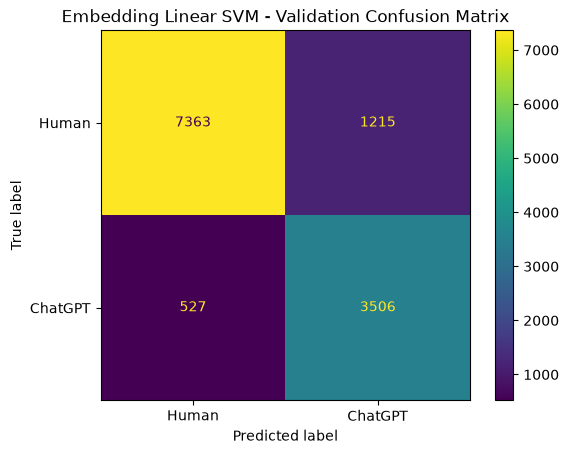

In [19]:
val_cm = confusion_matrix(
    y_validation,
    val_predictions
)

print("Validation Confusion Matrix:")
print(val_cm)

ConfusionMatrixDisplay(
    confusion_matrix=val_cm,
    display_labels=["Human", "ChatGPT"]
).plot()

plt.title(
    "Embedding Linear SVM - Validation Confusion Matrix"
)

plt.show()

## Evaluate on Test Data

Evaluate the embedding-based SVM model on the test set.

In [20]:
test_predictions = model.predict(X_test)

test_scores = model.decision_function(X_test)

print(
    "Test Accuracy:",
    accuracy_score(y_test, test_predictions)
)

print(
    "Test Macro Precision:",
    precision_score(
        y_test,
        test_predictions,
        average="macro"
    )
)

print(
    "Test Macro Recall:",
    recall_score(
        y_test,
        test_predictions,
        average="macro"
    )
)

print(
    "Test Macro F1:",
    f1_score(
        y_test,
        test_predictions,
        average="macro"
    )
)

print(
    "Test ROC-AUC:",
    roc_auc_score(
        y_test,
        test_scores
    )
)

Test Accuracy: 0.8635212159594681
Test Macro Precision: 0.8399468530818515
Test Macro Recall: 0.8647674692191155
Test Macro F1: 0.8493845419634831
Test ROC-AUC: 0.9403069315253967


Test Confusion Matrix:
[[7389 1190]
 [ 534 3519]]


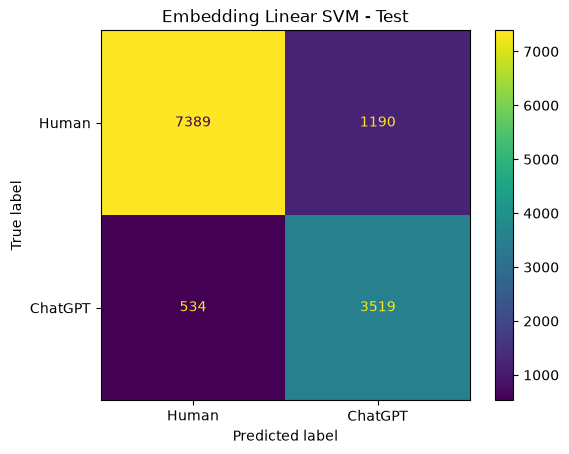

In [21]:
test_cm = confusion_matrix(
    y_test,
    test_predictions
)

print("Test Confusion Matrix:")
print(test_cm)

ConfusionMatrixDisplay(
    confusion_matrix=test_cm,
    display_labels=["Human", "ChatGPT"]
).plot()

plt.title(
    "Embedding Linear SVM - Test"
)

plt.show()

## ROC Curve

Visualize the Linear SVM model's ability to distinguish between human and ChatGPT-generated text across classification thresholds.

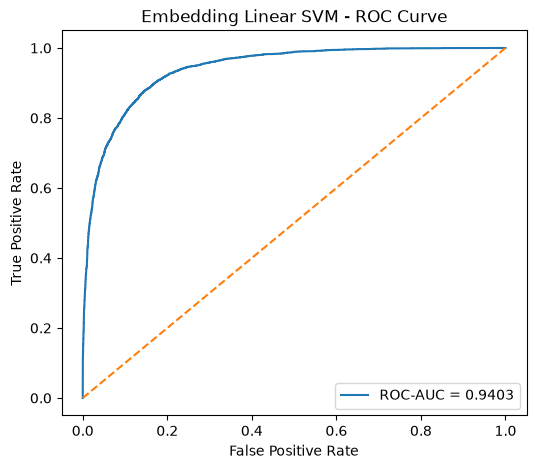

In [22]:
test_scores = model.decision_function(X_test)

fpr, tpr, thresholds = roc_curve(
    y_test,
    test_scores
)

test_auc = roc_auc_score(
    y_test,
    test_scores
)

plt.figure(figsize=(6, 5))

plt.plot(
    fpr,
    tpr,
    label=f"ROC-AUC = {test_auc:.4f}"
)

plt.plot(
    [0, 1],
    [0, 1],
    linestyle="--"
)

plt.xlabel("False Positive Rate")
plt.ylabel("True Positive Rate")
plt.title("Embedding Linear SVM - ROC Curve")
plt.legend()
plt.show()

## Save Model

Save the trained embedding-based SVM model for reuse and comparison.

In [15]:
svm_model_path = (
    EMBEDDINGS_MODEL_DIR
    / "linear_svm_embeddings.joblib"
)

joblib.dump(
    model,
    svm_model_path
)

print("Saved:")
print(svm_model_path)

Saved:
../../models/embeddings/linear_svm_embeddings.joblib
